# 2. Comparing models against IPSS-R

**Transplant or Wait** · Aya Bekhtiar, Apolline Hadjal

The brief requires a comparison against the reference score, IPSS-R. We compare four candidates with it, holding out **one centre at a time**: each model is fitted on 22 centres and scored on the 23rd, which is the closest this file comes to "another hospital" (Session 3).

| Candidate | What is estimated on this file |
| --- | --- |
| 1. IPSS-M, recalibrated | 2 numbers: slope from score to hazard, 2-year baseline survival |
| 2. Cox model on the 22 IPSS-M variables | 22 weights (elastic net) |
| 3. Cox model, 35 variables | adds neutrophils, WBC, monocytes, karyotype and mutation counts, 7 more genes |
| 4. Boosted trees, 35 variables | 300 shallow trees: is flexibility worth it? |

**Selection rule, written before the comparison was first run:** deploy the simplest candidate whose C-index is within 0.005 of the best, provided observed/expected 2-year deaths is between 0.9 and 1.1.

This notebook runs the whole comparison (about 6 minutes). It saves every result to `outputs/validation/` (including `selection.json`, which `scripts/03_train_final.py` reads to freeze the chosen model) and the report's figures F5–F9 to `outputs/figures/`.

In [1]:
import os, sys
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from mds_tool import HORIZON_YEARS, cohort, metrics, plotting, scores
plotting.setup()
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)
H = HORIZON_YEARS  # 2-year horizon

from mds_tool import TAU_YEARS
from mds_tool.model import EXTENDED_VARS, IPSSM_VARS, Boosted, LinearCox, ScoreRecalibrated
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.util import Surv

THRESHOLD = 0.30   # 2-year risk above which early transplant evaluation is supported
N_BOOT = 500       # bootstrap resamples for confidence intervals
colors = plotting.MODEL_COLORS

import json
OUT, FIG = "outputs/validation", "outputs/figures"
os.makedirs(OUT, exist_ok=True)
os.makedirs(FIG, exist_ok=True)

In [2]:
df = cohort.load_all()
steps, masks = cohort.flow(df)
pool = df[masks["has_outcome"]].copy()
pool["in_scope"] = masks["in_scope"][pool.index]
pool["h2h"] = masks["head_to_head"][pool.index]
print(f"patients with an outcome: {len(pool)}, intended use: {pool.in_scope.sum()}, head-to-head: {pool.h2h.sum()}")

patients with an outcome: 3120, intended use: 2662, head-to-head: 2382


## 1. Leave one centre out

Models are trained only on intended-use patients from the other 22 centres; the held-out centre's patients (in scope or not) are scored. Penalties for the Cox models are chosen by cross-validation across the training centres only.

**Speed.** The 23 centre fits are independent, so they run in parallel on all CPU cores. Their predictions are cached in `outputs/validation/` with a fingerprint of the two data files and the `mds_tool` code: when neither has changed, the notebook reloads them in seconds instead of refitting (a few minutes). To force a refit, set the environment variable `RECOMPUTE_LOCO=1` or run `./run_all.sh --fresh`. Every fit is deterministic, so refitting, in parallel or not, gives exactly the same numbers.

In [3]:
import glob, hashlib, time
from joblib import Parallel, delayed

MODELS = {
    "IPSS-R": lambda: ScoreRecalibrated("IPSSR_score", name="IPSS-R"),
    "IPSS-M": lambda: ScoreRecalibrated("IPSSM_score", name="IPSS-M"),
    "Cox (IPSS-M variables, refit)": lambda: LinearCox(IPSSM_VARS, l1_ratio=0.5, name="cox_ipssm"),
    "Cox (extended)": lambda: LinearCox(EXTENDED_VARS, l1_ratio=0.5, name="cox_ext"),
    "Boosted trees (extended)": lambda: Boosted(EXTENDED_VARS),
}
SIMPLICITY = ["IPSS-M", "Cox (IPSS-M variables, refit)", "Cox (extended)", "Boosted trees (extended)"]

def fit_centre(c, pool):
    """Fit every model without centre c, score centre c. Returns the scores and the chosen penalties."""
    train = pool[pool.in_scope & (pool.CENTER != c)]
    test = pool[pool.CENTER == c]
    lp_c, risk_c, alpha_c = {}, {}, {}
    for name, make in MODELS.items():
        tr = train[train.IPSSR_score.notna()] if name == "IPSS-R" else train
        m = make().fit(tr, groups=tr.CENTER.values)
        lp_c[name] = m.linear_predictor(test)
        risk_c[name] = m.risk_at_horizon(test)
        if hasattr(m, "alpha"):
            alpha_c[name] = m.alpha
    return test.index, lp_c, risk_c, alpha_c


def fingerprint():
    """Changes whenever the data files or the mds_tool code change."""
    h = hashlib.sha256()
    for p in ["df_clinical_train.tsv", "mut_clinical_train.tsv"] + sorted(glob.glob("mds_tool/*.py")):
        h.update(open(p, "rb").read())
    return h.hexdigest()[:16]

In [4]:
CACHE, PRED = f"{OUT}/loco_cache.json", f"{OUT}/oof_predictions.csv"
fp = fingerprint()
meta = json.load(open(CACHE)) if os.path.exists(CACHE) and os.path.exists(PRED) else {}
use_cache = meta.get("fingerprint") == fp and os.environ.get("RECOMPUTE_LOCO") != "1"

t0 = time.time()
if use_cache:
    saved = pd.read_csv(PRED, index_col=0, float_precision="round_trip").loc[pool.index]   # exact floats
    lp = saved[[f"lp_{n}" for n in MODELS]].set_axis(list(MODELS), axis=1)
    risk = saved[[f"risk2y_{n}" for n in MODELS]].set_axis(list(MODELS), axis=1)
    alphas = meta["alphas"]
    print(f"Loaded cached out-of-centre predictions (data and code unchanged, fingerprint {fp}) in {time.time() - t0:.1f}s")
else:
    os.environ["PYTHONPATH"] = ROOT + os.pathsep + os.environ.get("PYTHONPATH", "")   # lets workers import mds_tool
    centres = sorted(pool.CENTER.unique())
    results = Parallel(n_jobs=-1)(delayed(fit_centre)(c, pool) for c in centres)
    lp = pd.DataFrame(index=pool.index, columns=list(MODELS), dtype=float)    # risk score (higher = worse)
    risk = lp.copy()                                                         # predicted 2-year risk of death
    alphas = {}                                                              # penalties chosen per fold
    for idx, lp_c, risk_c, alpha_c in results:                               # in centre order
        for name in MODELS:
            lp.loc[idx, name] = lp_c[name]
            risk.loc[idx, name] = risk_c[name]
        for name, a in alpha_c.items():
            alphas.setdefault(name, []).append(a)
    lp.loc[pool.IPSSR_score.isna(), "IPSS-R"] = np.nan
    risk.loc[pool.IPSSR_score.isna(), "IPSS-R"] = np.nan
    oof = pd.concat([pool[["CENTER", "OS_YEARS", "OS_STATUS", "in_scope", "h2h"]],
                     lp.add_prefix("lp_"), risk.add_prefix("risk2y_")], axis=1)
    oof.to_csv(PRED)
    json.dump({"fingerprint": fp, "alphas": alphas}, open(CACHE, "w"), indent=1)
    print(f"Refitted 5 models x {len(centres)} centres in parallel in {time.time() - t0:.0f}s; cached in {OUT}/")

Loaded cached out-of-centre predictions (data and code unchanged, fingerprint 811447734667127a) in 0.0s


In [5]:
# every patient's out-of-centre risk score and 2-year risk, for each model
pd.concat([pool[["CENTER", "OS_YEARS", "OS_STATUS"]], lp.add_prefix("lp_"), risk.add_prefix("risk2y_")], axis=1).head()

,CENTER,OS_YEARS,OS_STATUS,lp_IPSS-R,lp_IPSS-M,"lp_Cox (IPSS-M variables, refit)",lp_Cox (extended),lp_Boosted trees (extended),risk2y_IPSS-R,risk2y_IPSS-M,"risk2y_Cox (IPSS-M variables, refit)",risk2y_Cox (extended),risk2y_Boosted trees (extended)
ID,,,,,,,,,,,,,
P132697,MSK,1.115068,1.0,0.846400,1.997441,2.120550,2.149163,1.375025,0.610551,0.942974,0.966184,0.970855,0.812694
P132698,MSK,4.928767,0.0,-0.512983,-0.261568,-0.094663,-0.180994,-0.161134,0.215090,0.258575,0.308992,0.291023,0.302653
P116889,MSK,2.043836,0.0,1.016323,0.423684,0.307707,0.094927,0.034462,0.672964,0.447696,0.424601,0.364419,0.354898
P132699,MSK,2.476712,1.0,0.336632,0.963755,1.077420,1.084938,0.939439,0.432442,0.638970,0.696794,0.704687,0.661604
P132700,MSK,3.145205,0.0,0.166709,-0.290604,-0.190453,-0.325249,-0.425239,0.379915,0.252200,0.285264,0.257499,0.241797


## 2. Discrimination and calibration on the head-to-head cohort

All metrics handle censoring: Harrell's and Uno's C-index, the time-dependent AUC at 2 years, the Brier score at 2 years (inverse-probability-of-censoring weighted), observed/expected 2-year deaths (Kaplan–Meier) and the calibration slope. Intervals: 95 % bootstrap percentiles.

In [6]:
def evaluate(sub, names, boot=True):
    t, e = sub.OS_YEARS.values, sub.OS_STATUS.values
    rows = {}
    for n in names:
        s, p = lp.loc[sub.index, n].values, risk.loc[sub.index, n].values
        r = dict(n=len(sub), deaths=int(e.sum()))
        r["harrell_c"] = metrics.harrell_c(t, e, s)
        r["uno_c_5y"] = metrics.uno_c(t, e, t, e, s, TAU_YEARS)
        r["auc_2y"] = metrics.td_auc(t, e, t, e, s, H)
        r["brier_2y"] = metrics.brier_at(t, e, t, e, 1 - p, H)
        obs, exp = metrics.calibration_in_the_large(t, e, p, H)
        r["observed_2y"], r["expected_2y"], r["o_e"] = obs, exp, obs / exp
        cll = np.log(-np.log(1 - np.clip(p, 1e-4, 1 - 1e-4)))
        r["cal_slope"] = float(CoxPHSurvivalAnalysis().fit(cll[:, None], Surv.from_arrays(e.astype(bool), t)).coef_[0])
        if boot:
            def f(idx, s=s, p=p):
                return [metrics.harrell_c(t[idx], e[idx], s[idx]),
                        metrics.td_auc(t[idx], e[idx], t[idx], e[idx], s[idx], H),
                        metrics.brier_at(t[idx], e[idx], t[idx], e[idx], 1 - p[idx], H)]
            lo, hi = metrics.bootstrap(f, len(sub), N_BOOT, seed=1)
            r.update(harrell_c_lo=lo[0], harrell_c_hi=hi[0], auc_2y_lo=lo[1], auc_2y_hi=hi[1],
                     brier_2y_lo=lo[2], brier_2y_hi=hi[2])
        rows[n] = r
    return pd.DataFrame(rows).T

h2h, ins, oos = pool[pool.h2h], pool[pool.in_scope], pool[~pool.in_scope]
res = evaluate(h2h, list(MODELS))
res.to_csv(f"{OUT}/metrics_head_to_head.csv")
res[["harrell_c", "harrell_c_lo", "harrell_c_hi", "uno_c_5y", "auc_2y", "auc_2y_lo", "auc_2y_hi",
     "brier_2y", "o_e", "cal_slope"]].astype(float).round(3)

,harrell_c,harrell_c_lo,harrell_c_hi,uno_c_5y,auc_2y,auc_2y_lo,auc_2y_hi,brier_2y,o_e,cal_slope
IPSS-R,0.707,0.691,0.723,0.688,0.754,0.732,0.776,0.186,0.988,0.971
IPSS-M,0.750,0.735,0.766,0.737,0.809,0.790,0.830,0.167,0.980,0.977
"Cox (IPSS-M variables, refit)",0.747,0.733,0.762,0.734,0.806,0.788,0.826,0.170,0.964,1.089
Cox (extended),0.746,0.733,0.762,0.735,0.802,0.782,0.823,0.171,0.958,1.158
Boosted trees (extended),0.742,0.728,0.758,0.730,0.800,0.779,0.821,0.171,0.949,1.134


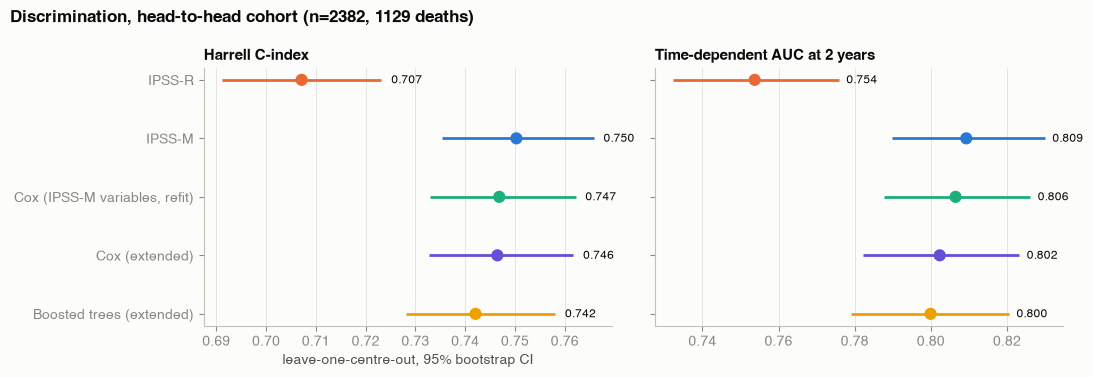

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, title in [(axes[0], "harrell_c", "Harrell C-index"), (axes[1], "auc_2y", "Time-dependent AUC at 2 years")]:
    r = res.iloc[::-1]
    y = np.arange(len(r))
    ax.hlines(y, r[col + "_lo"].astype(float), r[col + "_hi"].astype(float), color=[colors[m] for m in r.index], lw=2)
    ax.scatter(r[col].astype(float), y, color=[colors[m] for m in r.index], s=60, zorder=3)
    for yi, v, hi in zip(y, r[col].astype(float), r[col + "_hi"].astype(float)):
        ax.text(hi + 0.002, yi, f"{v:.3f}", va="center", fontsize=8.5)
    ax.set_yticks(y)
    ax.set_yticklabels(r.index if ax is axes[0] else [""] * len(r))
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
axes[0].set_xlabel("leave-one-centre-out, 95% bootstrap CI")
fig.suptitle(f"Discrimination, head-to-head cohort (n={len(h2h)}, {int(h2h.OS_STATUS.sum())} deaths)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
fig.savefig(f"{FIG}/F5_discrimination.png")
plt.show()

### Differences on the same patients (paired bootstrap)

In [8]:
def paired_diff(sub, a, b):
    t, e = sub.OS_YEARS.values, sub.OS_STATUS.values
    sa, sb = lp.loc[sub.index, a].values, lp.loc[sub.index, b].values
    d0 = metrics.harrell_c(t, e, sa) - metrics.harrell_c(t, e, sb)
    lo, hi = metrics.bootstrap(lambda i: metrics.harrell_c(t[i], e[i], sa[i]) - metrics.harrell_c(t[i], e[i], sb[i]),
                               len(sub), N_BOOT, seed=2)
    return dict(model=a, versus=b, delta_c=round(d0, 4), ci_low=round(float(lo), 4), ci_high=round(float(hi), 4))

others = [n for n in MODELS if n != "IPSS-R"]
diffs = pd.DataFrame([paired_diff(h2h, n, "IPSS-R") for n in others] +
                     [paired_diff(h2h, n, "IPSS-M") for n in others if n != "IPSS-M"])
diffs.to_csv(f"{OUT}/paired_c_differences.csv", index=False)
diffs

,model,versus,delta_c,ci_low,ci_high
0,IPSS-M,IPSS-R,0.0431,0.0324,0.0529
1,"Cox (IPSS-M variables, refit)",IPSS-R,0.0397,0.0288,0.0498
2,Cox (extended),IPSS-R,0.0393,0.0281,0.0495
3,Boosted trees (extended),IPSS-R,0.0349,0.0229,0.0446
4,"Cox (IPSS-M variables, refit)",IPSS-M,-0.0034,-0.0065,0.0002
5,Cox (extended),IPSS-M,-0.0038,-0.0084,0.0011
6,Boosted trees (extended),IPSS-M,-0.0082,-0.0152,-0.0018


### How much of IPSS-M's lead is home advantage?

IPSS-M was largely built on these patients (notebook 1), so its C-index is partly in-sample. The refitted 22-variable Cox model uses the same inputs but never sees the held-out centre: its C-index is the honest out-of-centre estimate.

In [9]:
home = res.loc["IPSS-M", "harrell_c"] - res.loc["Cox (IPSS-M variables, refit)", "harrell_c"]
print(f"IPSS-M {res.loc['IPSS-M', 'harrell_c']:.3f}  vs  refitted, out of centre {res.loc['Cox (IPSS-M variables, refit)', 'harrell_c']:.3f}"
      f"  ->  home advantage about {home:.3f}")

IPSS-M 0.750  vs  refitted, out of centre 0.747  ->  home advantage about 0.003


## 3. Applying the selection rule

In [10]:
best = res.loc[SIMPLICITY, "harrell_c"].astype(float).max()
chosen = next(n for n in SIMPLICITY
              if res.loc[n, "harrell_c"] >= best - 0.005 and 0.9 <= res.loc[n, "o_e"] <= 1.1)
print(f"best C-index {best:.3f}; chosen: {chosen}")
selection = dict(best_c=float(best), chosen=chosen,
                 rule="simplest within 0.005 of best pooled LOCO Harrell C (head-to-head) and O/E in [0.9, 1.1]",
                 candidates={n: dict(harrell_c=float(res.loc[n, "harrell_c"]), o_e=float(res.loc[n, "o_e"])) for n in SIMPLICITY},
                 alphas={k: [float(np.min(v)), float(np.median(v)), float(np.max(v))] for k, v in alphas.items()})
json.dump(selection, open(f"{OUT}/selection.json", "w"), indent=2)   # read by scripts/03_train_final.py
res.loc[SIMPLICITY, ["harrell_c", "o_e"]].astype(float).round(3)

best C-index 0.750; chosen: IPSS-M


,harrell_c,o_e
IPSS-M,0.750,0.980
"Cox (IPSS-M variables, refit)",0.747,0.964
Cox (extended),0.746,0.958
Boosted trees (extended),0.742,0.949


**IPSS-M, recalibrated** is kept: the more complex models do not beat it, and boosted trees are slightly worse.

## 4. Calibration at 2 years

Patients are grouped into deciles of predicted risk; the observed 2-year mortality in each decile is a Kaplan–Meier estimate (bars = 95 % Greenwood interval). Points on the diagonal mean the predicted percentage is right.

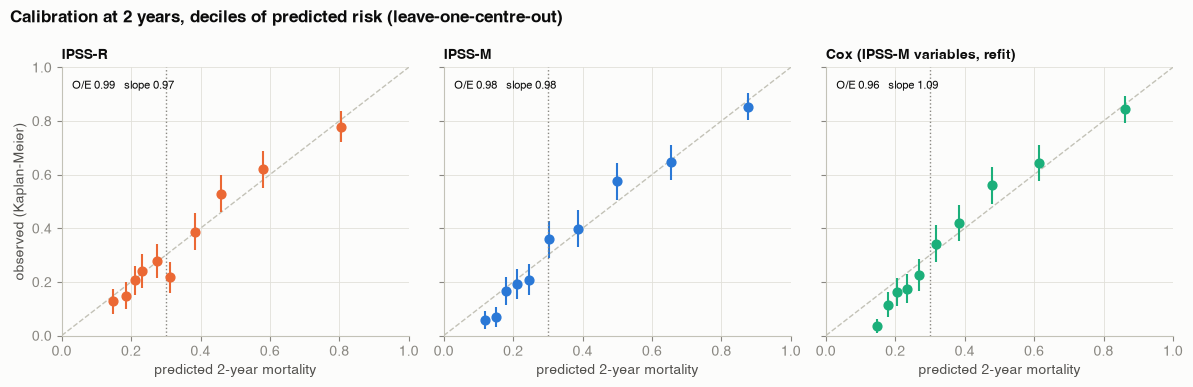

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9), sharey=True)
cal_rows = []
for ax, n in zip(axes, ["IPSS-R", "IPSS-M", "Cox (IPSS-M variables, refit)"]):
    ct = metrics.calibration_table(h2h.OS_YEARS.values, h2h.OS_STATUS.values, risk.loc[h2h.index, n].values, H, 10)
    cal_rows.append(ct.assign(model=n))
    ax.plot([0, 1], [0, 1], color=plotting.AXIS, lw=1, ls="--")
    ax.vlines(ct.predicted, ct.lo, ct.hi, color=colors[n], lw=1.5)
    ax.scatter(ct.predicted, ct.observed, color=colors[n], s=40, zorder=3)
    ax.axvline(THRESHOLD, color=plotting.MUTED, lw=1, ls=":")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_title(n, fontsize=10)
    ax.text(0.03, 0.92, f"O/E {res.loc[n, 'o_e']:.2f}   slope {res.loc[n, 'cal_slope']:.2f}", fontsize=8)
    ax.set_xlabel("predicted 2-year mortality")
axes[0].set_ylabel("observed (Kaplan-Meier)")
fig.suptitle("Calibration at 2 years, deciles of predicted risk (leave-one-centre-out)", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
plt.tight_layout()
fig.savefig(f"{FIG}/F6_calibration.png")
plt.show()
pd.concat(cal_rows).to_csv(f"{OUT}/calibration_deciles.csv", index=False)

## 5. At the decision: threshold 30 %

The 30 % threshold is the 2-year risk at the IPSS-M Moderate-Low / Moderate-High boundary, from which early transplant prolongs life expectancy (Tentori et al., JCO 2024). Sensitivity, specificity and predictive values are Kaplan–Meier estimates within the flagged and unflagged groups.

In [12]:
rules = {"IPSS-R > 3.5 (higher-risk)": h2h.IPSSR_score > 3.5,
         "IPSS-M Moderate-High or worse": h2h.IPSSM_score > 0,
         "Tool (IPSS-M recalibrated): 2-year risk >= 30%": risk.loc[h2h.index, "IPSS-M"] >= THRESHOLD}
rows = [dict(rule=k, **metrics.operating_point(h2h.OS_YEARS.values, h2h.OS_STATUS.values, v.values.astype(bool), H))
        for k, v in rules.items()]
pd.DataFrame(rows).to_csv(f"{OUT}/decision_policies_head_to_head.csv", index=False)
(pd.DataFrame(rows).set_index("rule") * 100).round(1).rename(columns=lambda c: c + " %")

,flagged %,sensitivity %,specificity %,ppv %,npv %
rule,,,,,
IPSS-R > 3.5 (higher-risk),39.6,65.1,74.8,58.5,79.8
IPSS-M Moderate-High or worse,43.5,73.8,74.0,60.3,84.4
Tool (IPSS-M recalibrated): 2-year risk >= 30%,45.4,75.5,71.8,59.2,84.8


### Decision curve

Net benefit counts the deaths within 2 years correctly flagged, minus the false flags weighted by the threshold's exchange rate (at 30 %, one unnecessary referral costs 3/7 of a correctly flagged death). A useful model must beat both "refer everyone" and "refer no one".

IPSS-R  net benefit at 30%: 0.159
IPSS-M  net benefit at 30%: 0.189
refer everyone at 30%: 0.079


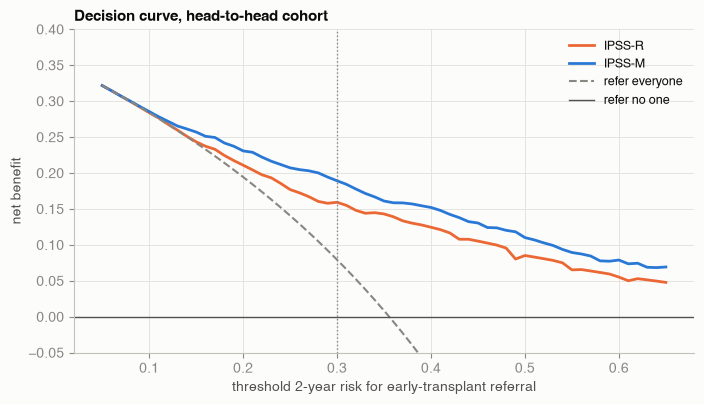

In [13]:
ths = np.round(np.arange(0.05, 0.66, 0.01), 2)
fig, ax = plt.subplots(figsize=(8, 4.2))
dca = []
for n in ["IPSS-R", "IPSS-M"]:
    nb = metrics.net_benefit(h2h.OS_YEARS.values, h2h.OS_STATUS.values, risk.loc[h2h.index, n].values, H, ths)
    dca.append(nb.assign(model=n))
    ax.plot(nb.threshold, nb.net_benefit, color=colors[n], label=n)
    print(f"{n:7s} net benefit at 30%: {nb.loc[nb.threshold == THRESHOLD, 'net_benefit'].item():.3f}")
print(f"refer everyone at 30%: {nb.loc[nb.threshold == THRESHOLD, 'treat_all'].item():.3f}")
ax.plot(nb.threshold, nb.treat_all, color=plotting.MUTED, ls="--", lw=1.5, label="refer everyone")
ax.axhline(0, color=plotting.INK2, lw=1, label="refer no one")
ax.axvline(THRESHOLD, color=plotting.MUTED, lw=1, ls=":")
ax.set_ylim(-0.05, 0.4)
ax.set_xlabel("threshold 2-year risk for early-transplant referral")
ax.set_ylabel("net benefit")
ax.set_title("Decision curve, head-to-head cohort")
ax.legend()
fig.savefig(f"{FIG}/F7_decision_curve.png")
plt.show()
pd.concat(dca).to_csv(f"{OUT}/decision_curve.csv", index=False)

### Who changes side compared with IPSS-R?

In [14]:
a = h2h.IPSSR_score > 3.5
b = risk.loc[h2h.index, "IPSS-M"] >= THRESHOLD
rows = []
for va in [False, True]:
    for vb in [False, True]:
        x = h2h[(a == va) & (b == vb)]
        rows.append({"IPSS-R": "higher risk" if va else "lower risk", "tool": "higher risk" if vb else "lower risk",
                     "patients": len(x), "2-year mortality %": round(100 * (1 - metrics.km_surv(x.OS_YEARS, x.OS_STATUS, H)), 1)})
reclass = pd.DataFrame(rows)
reclass.to_csv(f"{OUT}/reclassification_vs_ipssr.csv", index=False)
up = h2h[~a & b]
genes = ["ASXL1", "RUNX1", "SRSF2", "EZH2"]
print("moved up by the tool vs everyone:", {g: f"{up[g].mean():.0%} vs {h2h[g].mean():.0%}" for g in genes})
reclass

moved up by the tool vs everyone: {'ASXL1': '55% vs 25%', 'RUNX1': '33% vs 12%', 'SRSF2': '30% vs 16%', 'EZH2': '18% vs 6%'}


,IPSS-R,tool,patients,2-year mortality %
0,lower risk,lower risk,1186,14.7
1,lower risk,higher risk,253,45.7
2,higher risk,lower risk,115,21.2
3,higher risk,higher risk,828,63.2


## 6. Where performance degrades

The same out-of-centre predictions, broken down by subgroup (95 % bootstrap intervals, 200 resamples), including the two groups outside the intended use.

In [15]:
def subgroup(mask_dict, base, names):
    out = []
    for label, m in mask_dict.items():
        x = base[m.reindex(base.index).fillna(False).astype(bool)]
        for n in names:
            s, p = lp.loc[x.index, n], risk.loc[x.index, n]
            ok = s.notna()
            if ok.sum() < 25 or x[ok].OS_STATUS.sum() < 10:
                continue
            xs = x[ok]
            obs, exp = metrics.calibration_in_the_large(xs.OS_YEARS, xs.OS_STATUS, p[ok], H)
            ci = metrics.bootstrap(lambda i, xs=xs, s=s[ok].values: metrics.harrell_c(
                xs.OS_YEARS.values[i], xs.OS_STATUS.values[i], s[i]), len(xs), 200, seed=3)
            out.append(dict(subgroup=label, model=n, n=len(xs), deaths=int(xs.OS_STATUS.sum()),
                            harrell_c=metrics.harrell_c(xs.OS_YEARS, xs.OS_STATUS, s[ok]),
                            c_lo=float(ci[0]), c_hi=float(ci[1]), o_e=obs / exp))
    return pd.DataFrame(out)

short_fu = ["ROM", "FLO", "VU", "CGM", "UOXF", "CCH", "PV"]   # centres with median follow-up < 2.6 years
sg = pd.concat([
    subgroup({"All intended-use patients": pd.Series(True, index=ins.index),
              "Karyotype missing or unreadable": ins.CYTO_CAT.isna(),
              "Karyotype available": ins.CYTO_CAT.notna(),
              "No mutation recorded": ins.NO_MUT_RECORDED == 1,
              "TP53 mutated": ins.TP53_n > 0,
              "Marrow blasts 10-19 %": ins.BM_BLAST >= 10,
              "Marrow blasts < 5 %": ins.BM_BLAST < 5,
              "Monocytosis (possible CMML)": ins.CMML_LIKE,
              "ANC missing (imputed)": ins.ANC.isna(),
              "IPSS-M lower risk (score <= 0)": ins.IPSSM_score <= 0,
              "IPSS-M higher risk (score > 0)": ins.IPSSM_score > 0,
              "IPSS-M category uncertain (missing data)": ins.IPSSM_uncertain,
              "Short follow-up centres (median < 2.6 y)": ins.CENTER.isin(short_fu)}, ins, ["IPSS-R", "IPSS-M"]),
    subgroup({"OUT OF SCOPE: blasts >= 20 % (AML)": oos.OUT_BLAST_GE20,
              "OUT OF SCOPE: WBC >= 13 (MDS/MPN)": oos.OUT_WBC_GE13 & ~oos.OUT_BLAST_GE20}, oos, ["IPSS-R", "IPSS-M"])])
sg.to_csv(f"{OUT}/subgroups.csv", index=False)
sg.round(3)

,subgroup,model,n,deaths,harrell_c,c_lo,c_hi,o_e
0,All intended-use patients,IPSS-R,2410,1147,0.707,0.689,0.723,0.993
1,All intended-use patients,IPSS-M,2662,1299,0.746,0.732,0.760,1.000
2,Karyotype missing or unreadable,IPSS-M,252,152,0.725,0.681,0.767,1.157
3,Karyotype available,IPSS-R,2410,1147,0.707,0.689,0.723,0.993
4,Karyotype available,IPSS-M,2410,1147,0.750,0.735,0.764,0.985
5,No mutation recorded,IPSS-R,221,61,0.682,0.616,0.754,0.694
6,No mutation recorded,IPSS-M,244,66,0.665,0.608,0.750,0.906
7,TP53 mutated,IPSS-R,287,211,0.712,0.680,0.748,1.123
8,TP53 mutated,IPSS-M,309,230,0.720,0.684,0.754,1.075
9,Marrow blasts 10-19 %,IPSS-R,413,284,0.656,0.618,0.688,0.970


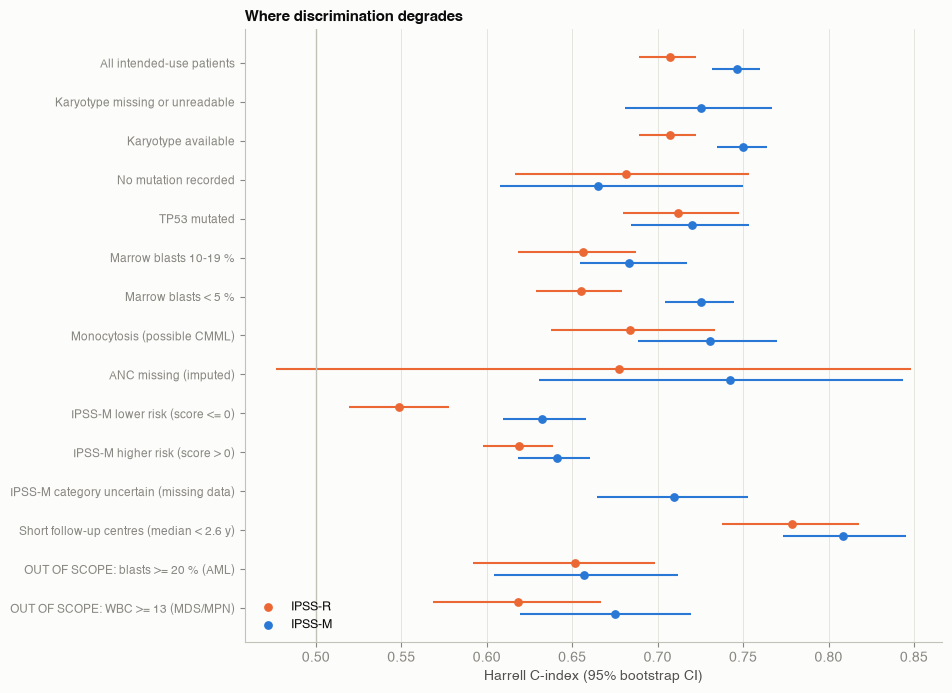

In [16]:
labels = list(dict.fromkeys(sg.subgroup))
fig, ax = plt.subplots(figsize=(9, 0.45 * len(labels) + 1.2))
for n, off in [("IPSS-R", -0.15), ("IPSS-M", 0.15)]:
    x = sg[sg.model == n]
    yy = [labels.index(l) + off for l in x.subgroup]
    ax.hlines(yy, x.c_lo, x.c_hi, color=colors[n], lw=1.5)
    ax.scatter(x.harrell_c, yy, color=colors[n], s=28, zorder=3, label=n)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=8.5)
ax.invert_yaxis()
ax.axvline(0.5, color=plotting.AXIS, lw=1)
ax.set_xlabel("Harrell C-index (95% bootstrap CI)")
ax.set_title("Where discrimination degrades")
ax.legend(loc="lower left")
ax.grid(axis="y", visible=False)
fig.savefig(f"{FIG}/F8_subgroups.png")
plt.show()

### By held-out centre

The ranking holds in every centre; the absolute risk does not: observed/expected 2-year deaths moves well outside 0.8–1.2 (grey band) in several centres.

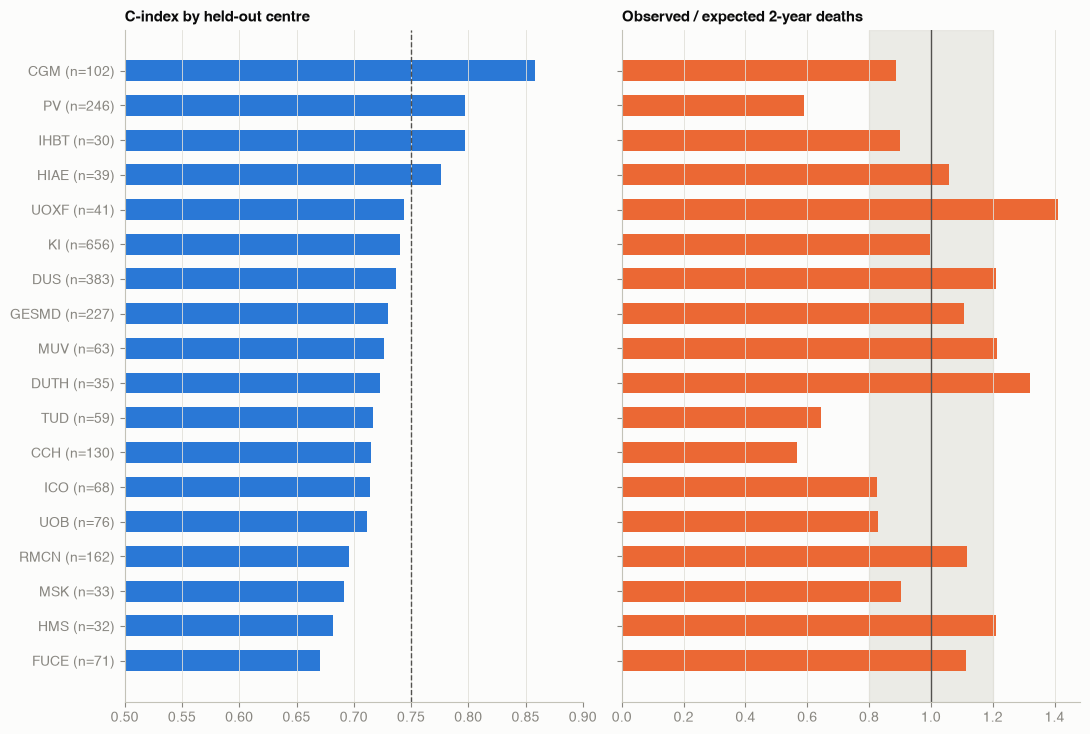

C-index range 0.67-0.86; observed/expected range 0.57-1.41


In [17]:
pc_all = []
for c, x in ins.groupby("CENTER"):
    if x.OS_STATUS.sum() < 15:
        continue
    for n in ["IPSS-R", "IPSS-M"]:
        ok = lp.loc[x.index, n].notna()
        if ok.sum() < 20:
            continue
        xs = x[ok]
        obs, exp = metrics.calibration_in_the_large(xs.OS_YEARS, xs.OS_STATUS, risk.loc[xs.index, n], H)
        pc_all.append(dict(centre=c, model=n, n=len(xs), deaths=int(xs.OS_STATUS.sum()),
                           harrell_c=metrics.harrell_c(xs.OS_YEARS, xs.OS_STATUS, lp.loc[xs.index, n]), o_e=obs / exp))
pc_all = pd.DataFrame(pc_all)
pc_all.to_csv(f"{OUT}/per_centre.csv", index=False)
pc = pc_all[pc_all.model == "IPSS-M"].sort_values("harrell_c")
lab = [f"{c} (n={n})" for c, n in zip(pc.centre, pc.n)]
fig, axes = plt.subplots(1, 2, figsize=(11, 0.33 * len(pc) + 1.5), sharey=True)
axes[0].barh(lab, pc.harrell_c, color=colors["IPSS-M"], height=0.6)
axes[0].axvline(res.loc["IPSS-M", "harrell_c"], color=plotting.INK2, ls="--", lw=1)
axes[0].set_xlim(0.5, 0.9)
axes[0].set_title("C-index by held-out centre")
axes[1].barh(lab, pc.o_e, color=plotting.SERIES[1], height=0.6)
axes[1].axvline(1, color=plotting.INK2, lw=1)
axes[1].axvspan(0.8, 1.2, color=plotting.GRID, alpha=0.6, zorder=0)
axes[1].set_title("Observed / expected 2-year deaths")
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout()
fig.savefig(f"{FIG}/F9_per_centre.png")
plt.show()
print(f"C-index range {pc.harrell_c.min():.2f}-{pc.harrell_c.max():.2f}; observed/expected range {pc.o_e.min():.2f}-{pc.o_e.max():.2f}")

## Conclusions

- IPSS-M ranks patients clearly better than IPSS-R (C-index +0.043, 95 % CI 0.032 to 0.053) and flags more of the patients who die within 2 years at a similar specificity.
- Refitting on this file, with more variables or with boosted trees, adds nothing; by the pre-specified rule the deployed model is **IPSS-M recalibrated to a 2-year risk**.
- IPSS-M's home advantage in this file is small (about 0.003).
- Main failure mode: **absolute risk differs between centres**, so local recalibration is needed before use. The tool also ranks poorly *within* the lower-risk group and outside its intended use.

→ **Notebook 3** freezes this model, shows its features and weights, and builds the bedside output.